In [122]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, GAE
import pandas as pd
import numpy as np
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
from torch_geometric.utils import from_scipy_sparse_matrix
from torch_geometric.data import Data
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt
from torch.nn import BatchNorm1d
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score, f1_score
import torch
import torch.nn.functional as F
from torch_geometric.nn import GCNConv
from torch.nn import BatchNorm1d
import matplotlib.pyplot as plt
import numpy as np
import random
import torch
import torch.nn.functional as F
from torch_geometric.nn import GATConv, BatchNorm
import numpy as np
import pandas as pd
import scipy.sparse as sp
from torch_geometric.data import Data
from torch_geometric.nn import GAE
from torch_geometric.utils import from_scipy_sparse_matrix

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)


In [124]:
############################################################################################################################################
### FUNCTIONS
############################################################################################################################################

# Define the GATEncoder architecture
class GATEncoder(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, num_layers=3, heads=4, dropout_rate=0.01):
        super(GATEncoder, self).__init__()
        self.num_layers = num_layers
        self.dropout_rate = dropout_rate
        
        # First layer: input to hidden size with multi-head attention
        self.convs = torch.nn.ModuleList()
        self.convs.append(GATConv(in_channels, hidden_channels, heads=heads, dropout=dropout_rate))
        
        # Add intermediate layers with attention
        for _ in range(num_layers - 2):
            self.convs.append(GATConv(heads * hidden_channels, hidden_channels, heads=heads, dropout=dropout_rate))
        
        # Final layer: hidden size to output size
        self.convs.append(GATConv(heads * hidden_channels, out_channels, heads=1, concat=False, dropout=dropout_rate))  # Single head for final layer
    
        # Batch normalization layers for each convolution layer
        self.bns = torch.nn.ModuleList([BatchNorm(hidden_channels * heads) for _ in range(num_layers - 1)])
    
        # Dropout rate
        self.dropout = torch.nn.Dropout(p=dropout_rate)
    
        # LeakyReLU instead of ReLU
        self.activation = torch.nn.LeakyReLU(negative_slope=0.05)
    
    def forward(self, x, edge_index):
        dead_neurons = []  # To track dead neurons across layers

        # First layer (without batch normalization)
        x = self.convs[0](x, edge_index)
        activations_1 = (x == 0).float().mean()  # Track how many activations are zero
        dead_neurons.append(activations_1.item())
        x = self.activation(x)
    
        # Intermediate layers with batch normalization and dropout
        for i in range(1, self.num_layers - 1):
            x_residual = x  # For residual connection
            x = self.convs[i](x, edge_index)
            x = self.bns[i - 1](x)  # Apply batch normalization
            activations_mid = (x == 0).float().mean()  # Track zero activations in hidden layers
            dead_neurons.append(activations_mid.item())
            #x = self.activation(x)
            x = F.relu(x)
            x = self.dropout(x)
            
            # Add residual connection (skip connection)
            x = x + x_residual
            
        # Final layer (no activation or batch norm)
        x = self.convs[-1](x, edge_index)
        activations_final = (x == 0).float().mean()  # Track zero activations in the final layer
        dead_neurons.append(activations_final.item())
        x = F.relu(x)

        return x

# Function to aggregate gene interactions across algorithms and use only those with >=2 hits
def aggregate_neighbors_across_algorithms(data, algorithms, min_hits=2):
    num_genes = data.shape[0]
    aggregated_adj = np.zeros((num_genes, num_genes))

    for alg in algorithms:
        alg_columns = [col for col in data.columns if col.startswith(alg + '.')]
        alg_matrix = data[alg_columns].values
        
        # For each algorithm, add 1 to the adjacency matrix where there is an interaction
        aggregated_adj += (alg_matrix > 0).astype(int)  # Binary conversion and add to aggregated_adj

    # Now, set entries to 0 where the interaction appears in fewer than 'min_hits' algorithms
    aggregated_adj[aggregated_adj < min_hits] = 0  # Remove interactions with less than 'min_hits' counts
    
    return aggregated_adj

# Apply GAE with GATEncoder to a combined adjacency matrix
def apply_gae_to_combined_adjacency(aggregated_adj, node_features, embedding_dim=8, epochs=200, dropout_rate=0.01, weight_decay=1e-4):
    # Convert adjacency matrix to sparse format
    adj_sparse = sp.csr_matrix(aggregated_adj)
    adj_normalized = normalize_adj(adj_sparse + sp.eye(adj_sparse.shape[0]))
    edge_index, edge_weight = from_scipy_sparse_matrix(adj_normalized)
    
    # Create data object
    x = torch.tensor(node_features, dtype=torch.float)
    data = Data(x=x, edge_index=edge_index)

    # Define the GATEncoder as the encoder for the GAE model
    encoder = GATEncoder(in_channels=x.shape[1], hidden_channels=embedding_dim, out_channels=embedding_dim, dropout_rate=dropout_rate)

    # Instantiate the GAE model by passing the encoder
    model = GAE(encoder)

    # Training settings
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = model.to(device)
    data = data.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=weight_decay)

    # Metrics to track
    losses = []
    accuracies = []

    # Training loop
    model.train()
    for epoch in range(1, epochs + 1):
        optimizer.zero_grad()

        # Forward pass
        z = model.encode(data.x, data.edge_index)

        # Reconstruction loss
        loss = model.recon_loss(z, data.edge_index)

        # Accuracy: Compare reconstruction with ground truth adjacency matrix
        adj_pred = (model.decoder.forward_all(z) > 0.5).float()  # Example threshold for prediction
        acc = (adj_pred == torch.tensor(aggregated_adj).float()).sum() / adj_pred.numel()  # Accuracy for all elements
        
        # Backward pass
        loss.backward()
        optimizer.step()

        # Store metrics
        losses.append(loss.item())
        accuracies.append(acc.item())

        # Print metrics every 50 epochs
        if epoch % 50 == 0:
            print(f'Epoch {epoch} | Loss: {loss.item():.4f} | Accuracy: {acc.item() * 100:.2f}%')

    # After training, reconstruct adjacency matrix
    model.eval()
    with torch.no_grad():
        z = model.encode(data.x, data.edge_index)
        adj_reconstructed = model.decoder.forward_all(z).cpu().numpy()
    
    return adj_reconstructed, losses, accuracies

# Function to run the combined GAE process
def run_gae_on_combined_neighbors(data, algorithms, node_features, embedding_dim=8, epochs=200, dropout_rate=0.01, min_hits=2):
    # Step 1: Aggregate neighbors across all algorithms
    print("Aggregating neighbors across algorithms (only >= 2 hits)...")
    aggregated_adj = aggregate_neighbors_across_algorithms(data, algorithms, min_hits=min_hits)
    
    # Step 2: Apply GAE to the combined adjacency matrix
    print("Applying GAE to combined adjacency matrix...")
    adj_reconstructed, losses, accuracies = apply_gae_to_combined_adjacency(aggregated_adj, node_features, embedding_dim, epochs, dropout_rate)

    return adj_reconstructed, losses, accuracies

In [126]:

# Normalize the adjacency matrix
def normalize_adj(adj):
    """Symmetrically normalize adjacency matrix."""
    adj = sp.coo_matrix(adj)
    rowsum = np.array(adj.sum(1)).flatten()
    d_inv_sqrt = np.power(rowsum + 1e-5, -0.5)
    d_inv_sqrt[np.isinf(d_inv_sqrt)] = 0.0
    d_mat_inv_sqrt = sp.diags(d_inv_sqrt)
    return adj.dot(d_mat_inv_sqrt).transpose().dot(d_mat_inv_sqrt).tocoo()

#normalized_laplacian
def normalize_adj(adj):
    """Compute the normalized Laplacian."""
    adj = sp.coo_matrix(adj)
    rowsum = np.array(adj.sum(1)).flatten()
    d_inv_sqrt = np.power(rowsum + 1e-5, -0.5)
    d_inv_sqrt[np.isinf(d_inv_sqrt)] = 0.0
    d_mat_inv_sqrt = sp.diags(d_inv_sqrt)
    identity = sp.eye(adj.shape[0])  # Identity matrix of the same size as adj
    laplacian = identity - d_mat_inv_sqrt.dot(adj).dot(d_mat_inv_sqrt)  # Normalized Laplacian
    return laplacian.tocoo()

#in_channels = 210  # Number of input features (e.g., time points or perturbations)
#hidden_channels = 64  # Hidden layer size
#out_channels = 32  # Output embedding size (could be adjusted based on your task)

# Instantiate the encoder

# Convert ground truth matrix to edge list
def convert_matrix_to_edge_list(matrix):
    edges = []
    for source in matrix.index:
        for target in matrix.columns:
            if matrix.at[source, target] == 1:
                edges.append((source, target))
    return edges


# Define the function to perform the GAE process for each threshold and multiple iterations
def run_gae_multiple_thresholds(data, ground_truth, algorithms, thresholds, num_iterations=30):
    num_genes = data.shape[0]
    #node_features = np.identity(num_genes)
    all_results = {}
    iteration_sums = {}

    for threshold in thresholds:
        print(f"Running for threshold: {threshold}")
        
        # Create a dictionary to store the results for each algorithm and threshold
        all_results[f'threshold_{threshold}'] = {}
        iteration_sums[f'threshold_{threshold}'] = {}

        # Initialize the iteration sum matrices for each threshold
        for iter_num in range(num_iterations):
            iteration_sums[f'threshold_{threshold}'][f'iter{iter_num + 1}_GCN_sum'] = np.zeros((num_genes, num_genes))

        for alg in algorithms:
            print(f"Running GAE for algorithm: {alg} with threshold: {threshold}")
            alg_columns = [col for col in data.columns if col.startswith(alg + '.')]
            alg_matrix = data[alg_columns].values

            # For each algorithm, create a list to store multiple runs
            all_results[f'threshold_{threshold}'][alg] = []

            for iteration in range(num_iterations):
                print(f"Iteration {iteration + 1}/{num_iterations} for algorithm: {alg}")
                
                # Apply GAE to the adjacency matrix of the algorithm
                adj_reconstructed, losses, accuracies = apply_gae_to_adjacency(alg_matrix, node_features)
                
                # Binarize the reconstructed adjacency matrix using the current threshold
                adj_binary = (adj_reconstructed > threshold).astype(int)

                # Store the binary adjacency matrix for this run
                all_results[f'threshold_{threshold}'][alg].append(adj_binary)

                # Add the binary matrix to the sum for this iteration and threshold
                iteration_sums[f'threshold_{threshold}'][f'iter{iteration + 1}_GCN_sum'] += adj_binary

    return all_results, iteration_sums

# Function to apply a second binarization threshold to the summed adjacency matrices
def apply_iteration_threshold(iteration_sums, thresholds, iter_thresholds):
    binary_sums = {}
    
    for threshold in thresholds:
        binary_sums[f'threshold_{threshold}'] = {}
        for iter_num in iteration_sums[f'threshold_{threshold}'].keys():
            binary_sums[f'threshold_{threshold}'][iter_num] = {}

            for iter_threshold in iter_thresholds:
                print(f"Applying iter_threshold {iter_threshold} to {iter_num} for threshold {threshold}")
                
                # Apply binarization on the summed adjacency matrix
                summed_matrix = iteration_sums[f'threshold_{threshold}'][iter_num]
                binary_matrix = (summed_matrix >= iter_threshold).astype(int)

                # Store the result
                binary_sums[f'threshold_{threshold}'][iter_num][f'iter_threshold_{iter_threshold}'] = binary_matrix
    
    return binary_sums

# Function to sum across iterations and apply a common threshold
def sum_across_iterations_and_binarize(binary_summed_matrices, thresholds, iter_thresholds, common_threshold):
    common_sums = {}

    for threshold in thresholds:
        common_sums[f'threshold_{threshold}'] = {}
        for iter_threshold in iter_thresholds:
            print(f"Summing across iterations for threshold {threshold} and iter_threshold {iter_threshold}")

            # Initialize the matrix for summing across iterations
            iteration_sum_matrix = np.zeros_like(binary_summed_matrices[f'threshold_{threshold}']['iter1_GCN_sum'][f'iter_threshold_{iter_threshold}'])

            # Sum the matrices across all iterations
            for iter_num in binary_summed_matrices[f'threshold_{threshold}'].keys():
                iteration_sum_matrix += binary_summed_matrices[f'threshold_{threshold}'][iter_num][f'iter_threshold_{iter_threshold}']

            # Apply the common threshold: if sum >= common_threshold, set 1; else set 0
            final_binarized_matrix = (iteration_sum_matrix >= common_threshold).astype(int)

            # Store the result
            common_sums[f'threshold_{threshold}'][f'iter_threshold_{iter_threshold}_common_threshold_{common_threshold}'] = final_binarized_matrix

    return common_sums


# Function to extract gene interactions (edges) from a binarized matrix
def extract_gene_interactions(final_matrix, gene_names):
    edges = []
    num_genes = final_matrix.shape[0]

    # Loop through the upper triangle of the matrix to avoid duplicates (since it's undirected)
    for i in range(num_genes):
        for j in range(i + 1, num_genes):
            if final_matrix[i, j] == 1:  # Check if there's an interaction
                edges.append(f"{gene_names[i]}-{gene_names[j]}")
    
    return edges


# Function to convert edges to consistent tuple format (e.g., ('G1', 'G10'))
def convert_edges_to_tuples(edge_list):
    edge_tuples = []
    for edge in edge_list:
        gene1, gene2 = edge.split('-')
        # Sort genes to maintain consistency in the edge representation (G1, G10) or (G10, G1)
        edge_tuples.append(tuple(sorted([gene1, gene2])))
    return set(edge_tuples)

# Function to compare predicted edges with known ground truth and generate the metrics
def compare_with_ground_truth(predicted_edges, known_edges_set):
    predicted_set = convert_edges_to_tuples(predicted_edges)
    
    # Calculate true positives and false positives
    true_positives = predicted_set.intersection(known_edges_set)
    false_positives = predicted_set.difference(known_edges_set)
    
    # Metrics
    num_true_positives = len(true_positives)
    num_false_positives = len(false_positives)
    
    return true_positives, false_positives, num_true_positives, num_false_positives



In [141]:
# Load the data
data = pd.read_csv("/Users/nirwantandukar/input_data/Database.DREAM4/NORMALIZED_EXP/normalized_weight_matrix_all_GRN_100_01_0.2filter.csv", index_col=0)
#data = pd.read_csv("/Users/nirwantandukar/input_data/weights_normalized/normalize_weight_matrix_all_GRN_100_01.csv", index_col=0)
print(f"Loaded data with shape: {data.shape}")

# Get the list of algorithms
columns = data.columns
algorithms = sorted(set(col.split('.')[0] for col in columns))
print(f"Algorithms found: {algorithms}")

num_genes = data.shape[0]
gene_names = data.index.tolist()
print(f"Number of genes: {num_genes}")

# Node features (identity matrix)
node_features = np.identity(num_genes)
#print(f"Node features shape: {node_features.shape}")


# Step 1: Load known (ground truth) interactions
file_path = "/Users/nirwantandukar/input_data/Database.DREAM4/GS/dream4_100_01_gs.csv"
ground_truth = pd.read_csv(file_path, index_col=0)
print(f"Ground truth loaded with shape: {ground_truth.shape}")

# Get the ground truth edges
known_edges_set = set(convert_matrix_to_edge_list(ground_truth))
print(f"Number of known edges: {len(known_edges_set)}")
# Define thresholds and number of iterations
#thresholds = [0.6, 0.8]  # Different thresholds to run
thresholds = [0.6]  # Different thresholds to run
num_iterations = 10  # Number of runs for each threshold

# Run the GAE process and store results for each threshold and algorithm
aggregated_results, iteration_sums = run_gae_multiple_thresholds(data, ground_truth, algorithms, thresholds, num_iterations)

# Define the additional binarization thresholds for the summed matrices
#iter_thresholds = [2,4,6, 8,10,12,14]  # Example thresholds for binarizing summed matrices
iter_thresholds = [4]  # Example thresholds for binarizing summed matrices

# Apply the iteration-level thresholding
binary_summed_matrices = apply_iteration_threshold(iteration_sums, thresholds, iter_thresholds)

# Example: Access binarized summed matrices for a specific iteration and iter_threshold
for threshold in thresholds:
    for iter_num in iteration_sums[f'threshold_{threshold}'].keys():
        for iter_threshold in iter_thresholds:
            binarized_matrix = binary_summed_matrices[f'threshold_{threshold}'][iter_num][f'iter_threshold_{iter_threshold}']
            print(f"Binarized adjacency matrix for {iter_num}, threshold {threshold}, iter_threshold {iter_threshold}:")
            print(binarized_matrix)

            # You can store or analyze these matrices further
            #output_file = f'binarized_{iter_num}_{threshold}_iter_thresh_{iter_threshold}.csv'
            #pd.DataFrame(binarized_matrix).to_csv(output_file)


# Define the common threshold
common_threshold = 9  # This is the threshold where if sum >= 30 across iterations, we set the value to 1. Consistently found in many iterations

# Sum across iterations and apply the common threshold
final_common_binarized_matrices = sum_across_iterations_and_binarize(binary_summed_matrices, thresholds, iter_thresholds, common_threshold)

# Example: Access and print the final binarized matrix for a specific threshold and iteration threshold
for threshold in thresholds:
    for iter_threshold in iter_thresholds:
        final_matrix = final_common_binarized_matrices[f'threshold_{threshold}'][f'iter_threshold_{iter_threshold}_common_threshold_{common_threshold}']
        print(f"Final binarized matrix for threshold {threshold}, iter_threshold {iter_threshold}, common_threshold {common_threshold}:")
        print(final_matrix)

        # You can save these matrices to CSV or further analyze them
        output_file = f'final_binarized_threshold_{threshold}_iter_thresh_{iter_threshold}_common_thresh_{common_threshold}.csv'
        #pd.DataFrame(final_matrix).to_csv(output_file)

# Assuming the gene names are the row/column names from your original data
gene_names = list(data.index)  # Replace 'data' with your actual DataFrame that contains the gene names

# Example: Use the final binarized matrix from the previous step (e.g., for threshold 0.8, iter_threshold 6, common_threshold 2)
for threshold in thresholds:
    for iter_threshold in iter_thresholds:
        final_matrix = final_common_binarized_matrices[f'threshold_{threshold}'][f'iter_threshold_{iter_threshold}_common_threshold_{common_threshold}']
        
        # Extract gene interactions (edges)
        edges = extract_gene_interactions(final_matrix, gene_names)
        
        # Print the edges
        print(f"Gene interactions for threshold {threshold}, iter_threshold {iter_threshold}, common_threshold {common_threshold}:")
        for edge in edges:
            print(edge)

        # Optionally, save the edges to a file
        output_file = f'gene_interactions_threshold_{threshold}_iter_thresh_{iter_threshold}_common_thresh_{common_threshold}.txt'
        with open(output_file, 'w') as f:
            for edge in edges:
                f.write(edge + '\n')

# Example structure to store the results
results = []



# Assume thresholds, iter_thresholds, and common_threshold are defined (as in the previous steps)
for threshold in thresholds:
    for iter_threshold in iter_thresholds:
        # For each final binarized matrix (e.g., threshold 0.8, iter_threshold 6, common_threshold 2)
        final_matrix = final_common_binarized_matrices[f'threshold_{threshold}'][f'iter_threshold_{iter_threshold}_common_threshold_{common_threshold}']
        
        # Extract gene interactions (predicted edges) from the final matrix
        predicted_edges = extract_gene_interactions(final_matrix, gene_names)
        
        # Compare predicted edges with the known ground truth edges
        true_positives, false_positives, num_true_positives, num_false_positives = compare_with_ground_truth(predicted_edges, known_edges_set)
        
        # Create a row for the results table
        results.append({
            'Iterations': num_iterations,
            'Common_Iterations': common_threshold,
            'Iter_Threshold': iter_threshold,
            'Individual_Threshold': threshold,
            'True_Positives': ','.join([f"{tp[0]}-{tp[1]}" for tp in true_positives]),  # Format as G1-G10
            'False_Positives': ','.join([f"{fp[0]}-{fp[1]}" for fp in false_positives]),  # Format as G1-G10
            'No_True_Positives': num_true_positives,
            'No_False_Positives': num_false_positives
        })

# Convert the results to a DataFrame for better visualization
results_df = pd.DataFrame(results)

# Display the results
print(results_df)

# Optionally, save the results to a CSV file
results_df.to_csv('true_false_positives_summary_GAT_combined.csv', index=False)

# Open a file to save the formatted AUROC and AUPRC results
with open('auroc_auprc_results.txt', 'w') as f:
    # Example: Compute AUROC and AUPRC for each final binarized matrix
    for threshold in thresholds:
        for iter_threshold in iter_thresholds:
            final_matrix = final_common_binarized_matrices[f'threshold_{threshold}'][f'iter_threshold_{iter_threshold}_common_threshold_{common_threshold}']
            
            # Compute AUROC and AUPRC
            auroc, auprc = compute_roc_and_prc(final_matrix, known_edges_set, gene_names)
            
            # Format the result strings
            auroc_line = f"AUROC for threshold {threshold}, iter_threshold {iter_threshold}: {auroc}\n"
            auprc_line = f"AUPRC for threshold {threshold}, iter_threshold {iter_threshold}: {auprc}\n"
            
            # Write the formatted results to the file
            f.write(auroc_line)
            f.write(auprc_line)

# Optionally, print a message when the file is saved
print("AUROC and AUPRC results have been saved to 'auroc_auprc_results_GAT_combined.txt'.")


Loaded data with shape: (100, 1700)
Algorithms found: ['GRN_ARACNE', 'GRN_BC3NET', 'GRN_C3NET', 'GRN_CLR', 'GRN_GENIE3_ET', 'GRN_GENIE3_RF', 'GRN_GRENIST', 'GRN_GRNBOOST2', 'GRN_INFERELATOR', 'GRN_KBOOST', 'GRN_LEAP', 'GRN_MEOMI', 'GRN_MRNET', 'GRN_MRNETB', 'GRN_NONLINEARODES', 'GRN_PCIT', 'GRN_TIGRESS']
Number of genes: 100
Ground truth loaded with shape: (100, 100)
Number of known edges: 175
Running for threshold: 0.6
Running GAE for algorithm: GRN_ARACNE with threshold: 0.6
Iteration 1/10 for algorithm: GRN_ARACNE
Epoch 50 | Loss: 1.1470 | Accuracy: 46.96%
Epoch 100 | Loss: 1.0570 | Accuracy: 69.50%
Epoch 150 | Loss: 1.0508 | Accuracy: 77.12%
Epoch 200 | Loss: 0.9979 | Accuracy: 79.93%
Iteration 2/10 for algorithm: GRN_ARACNE
Epoch 50 | Loss: 1.2844 | Accuracy: 25.03%
Epoch 100 | Loss: 1.0398 | Accuracy: 47.18%
Epoch 150 | Loss: 1.0253 | Accuracy: 64.36%
Epoch 200 | Loss: 1.0717 | Accuracy: 68.72%
Iteration 3/10 for algorithm: GRN_ARACNE
Epoch 50 | Loss: 1.1624 | Accuracy: 32.34%
Ep

NameError: name 'compute_roc_and_prc' is not defined

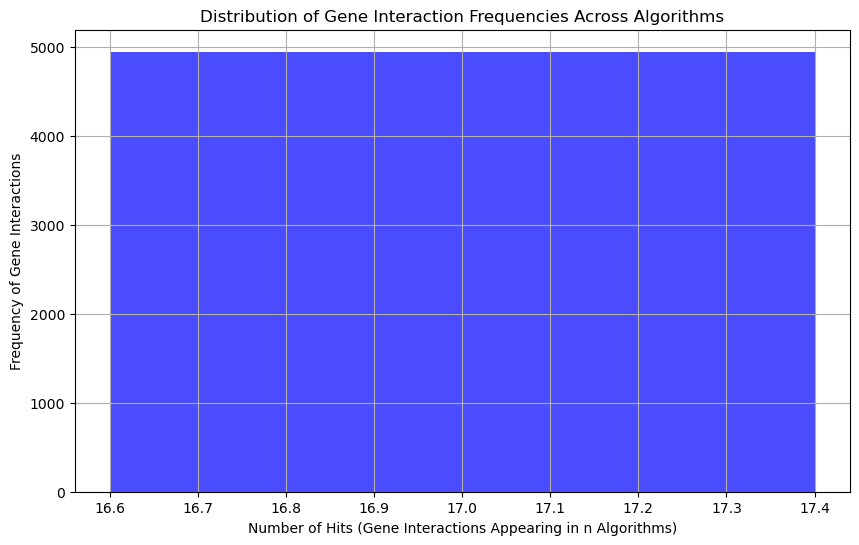

   Hits  Frequency
0  17.0       4950


<Figure size 640x480 with 0 Axes>

In [139]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Assuming 'data' is your full DataFrame containing all 17 adjacency matrices as columns (each algorithm as a column).

def count_gene_interaction_hits(data, gene_names):
    """
    Count how many times each gene interaction appears across all algorithms.
    
    :param data: Pandas DataFrame where each column is an adjacency matrix from an algorithm.
    :param gene_names: List of gene names corresponding to the rows/columns of the matrices.
    :return: DataFrame with the count of appearances (hits) for each gene interaction.
    """
    num_genes = data.shape[0]
    
    # Initialize a matrix to count the number of hits per gene pair
    hit_count = np.zeros((num_genes, num_genes))
    
    # For each pair of genes (i, j), count how many algorithms predict an interaction (non-zero value)
    for i in range(num_genes):
        for j in range(i + 1, num_genes):  # Avoid repeating symmetric pairs
            # Sum the number of non-zero values for this gene pair across all algorithms
            hit_count[i, j] = np.sum(data.iloc[i, j::num_genes].values > 0)
    
    # Convert the result into a DataFrame
    interaction_list = []
    for i in range(num_genes):
        for j in range(i + 1, num_genes):  # Only upper triangular matrix
            interaction_list.append({
                'Gene_Pair': f'{gene_names[i]}-{gene_names[j]}',
                'Hits': hit_count[i, j]
            })
    
    return pd.DataFrame(interaction_list)

# Example usage with your data
gene_names = list(data.index)  # Assuming the row/column names are gene names
hit_counts_df = count_gene_interaction_hits(data, gene_names)

# Now let's group by the number of hits and count how many gene pairs fall into each group
hit_frequency_df = hit_counts_df.groupby('Hits').size().reset_index(name='Frequency')

# Plot the frequency of gene interactions based on the number of hits (appearances)
plt.figure(figsize=(10, 6))
plt.bar(hit_frequency_df['Hits'], hit_frequency_df['Frequency'], color='blue', alpha=0.7)
plt.title('Distribution of Gene Interaction Frequencies Across Algorithms')
plt.xlabel('Number of Hits (Gene Interactions Appearing in n Algorithms)')
plt.ylabel('Frequency of Gene Interactions')
plt.grid(True)
plt.show()

# Optionally, save the plot
plt.savefig('gene_interaction_frequency_distribution.png')

# Print the table showing the frequency of gene interactions
print(hit_frequency_df)


In [ ]:
interactions_df

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Assuming 'data' is your full DataFrame containing all 17 adjacency matrices as columns (each algorithm as a column).

def count_gene_interaction_hits(data, gene_names):
    """
    Count how many times each gene interaction appears across all algorithms.
    
    :param data: Pandas DataFrame where each column is an adjacency matrix from an algorithm.
    :param gene_names: List of gene names corresponding to the rows/columns of the matrices.
    :return: DataFrame with the count of appearances (hits) for each gene interaction.
    """
    num_genes = data.shape[0]
    
    # Initialize a matrix to count the number of hits per gene pair
    hit_count = np.zeros((num_genes, num_genes))
    
    # For each pair of genes (i, j), count how many algorithms predict an interaction (non-zero value)
    for i in range(num_genes):
        for j in range(i + 1, num_genes):  # Avoid repeating symmetric pairs
            # Sum the number of non-zero values for this gene pair across all algorithms
            hit_count[i, j] = np.sum(data.iloc[i, j::num_genes].values > 0)
    
    # Convert the result into a DataFrame
    interaction_list = []
    for i in range(num_genes):
        for j in range(i + 1, num_genes):  # Only upper triangular matrix
            interaction_list.append({
                'Gene_Pair': f'{gene_names[i]}-{gene_names[j]}',
                'Hits': hit_count[i, j]
            })
    
    return pd.DataFrame(interaction_list)

# Example usage with your data
gene_names = list(data.index)  # Assuming the row/column names are gene names
hit_counts_df = count_gene_interaction_hits(data, gene_names)

# Subset gene interactions with hits >= 2
filtered_hit_counts_df = hit_counts_df[hit_counts_df['Hits'] >= 2]

# Now let's group by the number of hits and count how many gene pairs fall into each group
hit_frequency_df = filtered_hit_counts_df.groupby('Hits').size().reset_index(name='Frequency')

# Plot the frequency of gene interactions based on the number of hits (appearances)
plt.figure(figsize=(10, 6))
plt.bar(hit_frequency_df['Hits'], hit_frequency_df['Frequency'], color='green', alpha=0.7)
plt.title('Distribution of Gene Interaction Frequencies (Hits >= 2)')
plt.xlabel('Number of Hits (Gene Interactions Appearing in n Algorithms)')
plt.ylabel('Frequency of Gene Interactions')
plt.grid(True)
plt.show()

# Optionally, save the plot
plt.savefig('filtered_gene_interaction_frequency_distribution.png')

# Print the table showing the frequency of gene interactions with hits >= 2
print(hit_frequency_df)


In [ ]:
filtered_hit_counts_df

In [ ]:
# Assuming 'filtered_hit_counts_df' is the DataFrame you showed above with the filtered gene pairs and hits >= 2.

def subset_gene_interactions_from_algorithms(data, filtered_hit_counts_df, gene_names):
    """
    Subset the original data for all algorithms, keeping only the gene interactions
    that are present in 'filtered_hit_counts_df'.
    
    :param data: The original DataFrame containing all adjacency matrices (one per algorithm).
    :param filtered_hit_counts_df: The DataFrame containing filtered gene pairs with hits >= 2.
    :param gene_names: List of gene names corresponding to the rows/columns of the matrices.
    :return: A new DataFrame with only the filtered interactions for each algorithm.
    """
    # Create an empty DataFrame to store the filtered results for each algorithm
    filtered_data = pd.DataFrame(index=data.index, columns=data.columns)
    
    # Loop over each gene interaction in the filtered_hit_counts_df
    for _, row in filtered_hit_counts_df.iterrows():
        # Extract the gene pair
        gene_pair = row['Gene_Pair']
        gene1, gene2 = gene_pair.split('-')
        
        # Find the indices for the gene names in the original data
        i = gene_names.index(gene1)
        j = gene_names.index(gene2)
        
        # For each algorithm, copy the values of the interaction from the original data
        # Use both (i, j) and (j, i) because the matrix is symmetric
        filtered_data.iloc[i, j::len(gene_names)] = data.iloc[i, j::len(gene_names)].values
        filtered_data.iloc[j, i::len(gene_names)] = data.iloc[j, i::len(gene_names)].values
    
    # Drop any NaN columns (if any were left empty)
    filtered_data.dropna(axis=1, how='all', inplace=True)
    
    return filtered_data

# Now, subset the original data based on the filtered interactions (hits >= 2)
filtered_data = subset_gene_interactions_from_algorithms(data, filtered_hit_counts_df, gene_names)

# Display the filtered data
print(filtered_data)


In [ ]:
import torch
import torch.nn.functional as F
import pandas as pd
import numpy as np
from torch_geometric.nn import GATConv
from torch_geometric.data import Data

# Function to extract the interaction values for each gene pair across all algorithms
def extract_gene_pair_interactions(data, gene_pair, gene_names):
    gene1, gene2 = gene_pair.split('-')
    i = gene_names.index(gene1)
    j = gene_names.index(gene2)
    
    # Extract values across all algorithms for this gene pair (both i,j and j,i for symmetry)
    interaction_values = data.iloc[i, j::len(gene_names)].values
    return interaction_values

# Define the GAT model
class GATAttention(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, heads=8, dropout_rate=0.01):
        super(GATAttention, self).__init__()
        self.gat = GATConv(in_channels, hidden_channels, heads=heads, dropout=dropout_rate, concat=False)
        self.dropout = torch.nn.Dropout(p=dropout_rate)
        self.activation = torch.nn.LeakyReLU(negative_slope=0.05)
    
    def forward(self, x, edge_index):
        x, att_weights = self.gat(x, edge_index, return_attention_weights=True)
        return self.activation(x), att_weights[1]  # Extract the actual attention weights (att_weights[1])

# Apply GAT for each algorithm separately and calculate attention scores
def calculate_attention_for_gene_pairs_per_algorithm(filtered_hit_counts_df, data, gene_names, embedding_dim=16, epochs=200, dropout_rate=0.01):
    attention_scores = []
    
    # Loop over each gene pair
    for _, row in filtered_hit_counts_df.iterrows():
        gene_pair = row['Gene_Pair']
        print(f"Processing {gene_pair}...")
        
        # Extract interaction values for this gene pair across all algorithms
        interaction_values = extract_gene_pair_interactions(data, gene_pair, gene_names)
        
        # Filter out zero interactions (we only want actual connections)
        non_zero_interactions = interaction_values[interaction_values != 0]
        
        # If no non-zero interactions, skip this gene pair
        if len(non_zero_interactions) == 0:
            print(f"Skipping {gene_pair} (all zeros).")
            continue
        
        # Step 4: Prepare data for GAT (run it on each algorithm's interaction values)
        individual_attention_scores = []
        
        # **Create asymmetric node features** (different features for each gene in the pair)
        # Let's assume node1 gets the algorithm value, and node2 gets a slightly modified value (random noise added)
        for alg_value in non_zero_interactions:
            node_features = torch.tensor([[alg_value], [alg_value + np.random.normal(0, 0.1)]], dtype=torch.float)  # Asymmetric node features
            
            # Create a simple edge index for a 2-node graph (G1-G2), symmetric
            edge_index = torch.tensor([[0, 1], [1, 0]], dtype=torch.long)  # Edge between G1 and G2
            
            # Initialize the GAT model
            model = GATAttention(in_channels=1, hidden_channels=embedding_dim, dropout_rate=dropout_rate)
            optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
            
            # Training loop
            model.train()
            for epoch in range(epochs):
                optimizer.zero_grad()
                z, att_weights = model(node_features, edge_index)  # Get attention weights
                
                # Fix loss: match the dimensions of the node features and GAT output
                node_features_resized = node_features.expand_as(z)  # Expand node features to match the size of z
                loss = F.mse_loss(z, node_features_resized)
                loss.backward()
                optimizer.step()
            
            # After training, extract attention weights
            model.eval()
            with torch.no_grad():
                _, att_weights = model(node_features, edge_index)
            
            # Append the attention score for this algorithm
            individual_attention_scores.append(att_weights.mean().item())
        
        # Average the attention scores across non-zero algorithms for this gene pair
        avg_attention_score = np.mean(individual_attention_scores)
        
        # Store the averaged attention score and gene pair
        attention_scores.append({
            'Gene_Pair': gene_pair,
            'Average_Attention_Score': avg_attention_score
        })
    
    # Step 5: Convert the attention scores to a DataFrame and sort by attention score
    attention_df = pd.DataFrame(attention_scores)
    attention_df = attention_df.sort_values(by='Average_Attention_Score', ascending=False).reset_index(drop=True)
    
    return attention_df

# Example usage with your data
gene_names = list(data.index)  # Assuming the row/column names are gene names
attention_df = calculate_attention_for_gene_pairs_per_algorithm(filtered_hit_counts_df, data, gene_names, embedding_dim=8, epochs=200, dropout_rate=0.01)

# Print and rank the attention scores
print(attention_df)


In [ ]:
gene_names = list(data.index)  # Assuming the row/column names are gene names
gene_names

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import scipy.sparse as sp
from torch_geometric.utils import from_scipy_sparse_matrix
from torch_geometric.data import Data
from torch_geometric.nn import GAE, GATConv, BatchNorm

# Define the GATEncoder architecture with attention weights
class GATEncoder(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, num_layers=3, heads=4, dropout_rate=0.01):
        super(GATEncoder, self).__init__()
        self.num_layers = num_layers
        self.dropout_rate = dropout_rate
        
        # First layer: input to hidden size with multi-head attention
        self.convs = torch.nn.ModuleList()
        self.convs.append(GATConv(in_channels, hidden_channels, heads=heads, dropout=dropout_rate, concat=True))
        
        # Add intermediate layers with attention
        for _ in range(num_layers - 2):
            self.convs.append(GATConv(heads * hidden_channels, hidden_channels, heads=heads, dropout=dropout_rate, concat=True))
        
        # Final layer: hidden size to output size
        self.convs.append(GATConv(heads * hidden_channels, out_channels, heads=1, concat=False, dropout=dropout_rate))  # Single head for final layer
    
        # Batch normalization layers for each convolution layer
        self.bns = torch.nn.ModuleList([BatchNorm(hidden_channels * heads) for _ in range(num_layers - 1)])
    
        # Dropout rate
        self.dropout = torch.nn.Dropout(p=dropout_rate)
    
        # LeakyReLU instead of ReLU
        self.activation = torch.nn.LeakyReLU(negative_slope=0.05)
    
    def forward(self, x, edge_index):
        attention_weights = []  # To store attention weights

        # First layer (without batch normalization)
        x, att_weights = self.convs[0](x, edge_index, return_attention_weights=True)  # Get attention weights
        attention_weights.append(att_weights)  # Store attention weights for the first layer
        x = self.activation(x)
    
        # Intermediate layers with batch normalization and dropout
        for i in range(1, self.num_layers - 1):
            x_residual = x  # For residual connection
            x, att_weights = self.convs[i](x, edge_index, return_attention_weights=True)  # Get attention weights
            attention_weights.append(att_weights)  # Store attention weights for intermediate layers
            x = self.bns[i - 1](x)  # Apply batch normalization
            x = F.relu(x)
            x = self.dropout(x)
            x = x + x_residual  # Add residual connection
            
        # Final layer (no activation or batch norm)
        x, _ = self.convs[-1](x, edge_index, return_attention_weights=False)  # Final layer, no attention weights needed
        x = F.relu(x)

        return x, attention_weights

# Function to aggregate gene interactions across algorithms and use only those with >=2 hits
def subset_gene_interactions(data, algorithms, min_hits=2):
    """
    Subset gene interactions that appear in at least `min_hits` algorithms.
    """
    num_genes = data.shape[0]
    hit_count = np.zeros((num_genes, num_genes))

    # Count how many times each gene interaction appears across all algorithms
    for alg in algorithms:
        alg_columns = [col for col in data.columns if col.startswith(alg + '.')]
        alg_matrix = data[alg_columns].values
        hit_count += (alg_matrix > 0).astype(int)  # Binary conversion and sum up

    # Subset the interactions that appear in at least `min_hits` algorithms
    filtered_adj = np.where(hit_count >= min_hits, 1, 0)
    
    return filtered_adj

# Apply GAE with GATEncoder to a combined adjacency matrix and extract attention weights
def apply_gae_to_combined_adjacency_with_attention(aggregated_adj, node_features, embedding_dim=8, epochs=200, dropout_rate=0.01, weight_decay=1e-4):
    # Convert adjacency matrix to sparse format
    adj_sparse = sp.csr_matrix(aggregated_adj)
    adj_normalized = normalize_adj(adj_sparse + sp.eye(adj_sparse.shape[0]))
    edge_index, edge_weight = from_scipy_sparse_matrix(adj_normalized)
    
    # Create data object
    x = torch.tensor(node_features, dtype=torch.float)
    data = Data(x=x, edge_index=edge_index)

    # Define the GATEncoder as the encoder for the GAE model
    encoder = GATEncoder(in_channels=x.shape[1], hidden_channels=embedding_dim, out_channels=embedding_dim, dropout_rate=dropout_rate)

    # Instantiate the GAE model by passing the encoder
    model = GAE(encoder)

    # Training settings
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = model.to(device)
    data = data.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=weight_decay)

    # Training loop
    model.train()
    for epoch in range(1, epochs + 1):
        optimizer.zero_grad()

        # Forward pass
        z, attention_weights = model.encode(data.x, data.edge_index)

        # Reconstruction loss
        loss = model.recon_loss(z, data.edge_index)

        # Backward pass
        loss.backward()
        optimizer.step()

        # Print metrics every 50 epochs
        if epoch % 50 == 0:
            print(f'Epoch {epoch} | Loss: {loss.item():.4f}')
    
    # After training, reconstruct adjacency matrix
    model.eval()
    with torch.no_grad():
        z, attention_weights = model.encode(data.x, data.edge_index)
        adj_reconstructed = model.decoder.forward_all(z).cpu().numpy()
    
    return adj_reconstructed

# Function to run multiple GAE processes, compare with gold standard, and find common interactions
def run_multiple_gae_and_compare_with_gold(data, algorithms, node_features, embedding_dim=8, epochs=200, dropout_rate=0.01, min_hits=2, num_runs=10, min_occurrences=8, gold_standard=None):
    num_genes = data.shape[0]

    # Step 1: Subset gene interactions that appear in at least `min_hits` algorithms
    filtered_adj = subset_gene_interactions(data, algorithms, min_hits=min_hits)
    
    # Initialize a matrix to sum the occurrences of interactions across runs
    interaction_sums = np.zeros((num_genes, num_genes))
    total_true_positives = 0
    total_false_positives = 0

    # Step 2: Run GAE multiple times and track interactions
    for run in range(num_runs):
        print(f"Run {run + 1}/{num_runs}...")
        adj_reconstructed = apply_gae_to_combined_adjacency_with_attention(filtered_adj, node_features, embedding_dim, epochs, dropout_rate)[0]
        
        # Binarize the reconstructed adjacency matrix (e.g., interaction present if value > 0.5)
        adj_binary = (adj_reconstructed > 0.5).astype(int)
        
        # Compare with gold standard for True Positives (TP) and False Positives (FP)
        true_positives, false_positives = compare_with_gold_standard(adj_binary, gold_standard)
        total_true_positives += true_positives
        total_false_positives += false_positives

        # Sum the occurrences of each interaction across runs
        interaction_sums += adj_binary
    
    # Step 3: Identify interactions that occur in at least `min_occurrences` runs
    common_interactions = (interaction_sums >= min_occurrences).astype(int)
    
    return common_interactions, total_true_positives, total_false_positives

# Function to compare predicted interactions with the gold standard (ground truth)
def compare_with_gold_standard(predicted_adj, gold_standard):
    """
    Compare the predicted adjacency matrix with the gold standard.
    
    Returns the number of true positives (TP) and false positives (FP).
    """
    true_positives = np.sum((predicted_adj == 1) & (gold_standard == 1))
    false_positives = np.sum((predicted_adj == 1) & (gold_standard == 0))
    
    return true_positives, false_positives

# Function to extract gene interactions (edges) from a binarized matrix
def extract_gene_interactions(common_interactions, gene_names):
    edges = []
    num_genes = common_interactions.shape[0]

    # Loop through the upper triangle of the matrix to avoid duplicates (since it's undirected)
    for i in range(num_genes):
        for j in range(i + 1, num_genes):
            if common_interactions[i, j] == 1:  # Check if there's an interaction
                edges.append(f"{gene_names[i]}-{gene_names[j]}")
    
    return edges

# Example usage:
data = pd.read_csv("/Users/nirwantandukar/input_data/Database.DREAM4/NORMALIZED_EXP/normalized_weight_matrix_all_GRN_100_01_0.4filter.csv", index_col=0)
gold_standard = pd.read_csv("/Users/nirwantandukar/input_data/Database.DREAM4/GS/dream4_100_01_gs.csv", index_col=0).values  # Gold standard matrix
algorithms = sorted(set(col.split('.')[0] for col in data.columns))
num_genes = data.shape[0]
node_features = np.identity(num_genes)
gene_names = list(data.index)

# Run the GAE multiple times (e.g., 10 runs), compare with gold standard, and find common interactions
common_interactions, total_true_positives, total_false_positives = run_multiple_gae_and_compare_with_gold(
    data, algorithms, node_features, embedding_dim=8, epochs=200, dropout_rate=0.01, min_hits=2, num_runs=10, min_occurrences=8, gold_standard=gold_standard
)

# Extract and print the common gene interactions
common_edges = extract_gene_interactions(common_interactions, gene_names)
print("Common gene interactions found in at least 8 runs:")
for edge in common_edges:
    print(edge)

# Print True Positives (TP) and False Positives (FP) across all runs
print(f"Total True Positives: {total_true_positives}")
print(f"Total False Positives: {total_false_positives}")


In [ ]:
common_edges